In [3]:
import cv2
import numpy as np
import os
from IPython.display import display, Image

# 경로
base_dir = r"C:\Users\KDS-30\Desktop\class\08_image_bible\darknet"

cfg_path = os.path.join(base_dir, "cfg", "yolov3.cfg")
weights_path = os.path.join(base_dir, "yolov3.weights")
image_path = os.path.join(base_dir, "data", "dog.jpg")
names_path = os.path.join(base_dir, "data", "coco.names")

# 파일 확인
print("cfg:", os.path.exists(cfg_path))
print("weights:", os.path.exists(weights_path))
print("image:", os.path.exists(image_path))
print("names:", os.path.exists(names_path))

cfg: True
weights: True
image: True
names: True


In [4]:
# 클래스 이름 불러오기
with open(names_path, "r") as f:
    classes = [line.strip() for line in f.readlines()]

# YOLOv3 모델 불러오기
net = cv2.dnn.readNetFromDarknet(cfg_path, weights_path)

# CPU 사용
net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)

# 출력 레이어 이름
layer_names = net.getLayerNames()
output_layers = net.getUnconnectedOutLayersNames()

print("모델 로드 완료")

모델 로드 완료


In [5]:
image = cv2.imread(image_path)

if image is None:
    raise ValueError("dog.jpg를 불러오지 못했습니다.")

height, width = image.shape[:2]

blob = cv2.dnn.blobFromImage(
    image,
    scalefactor=1 / 255.0,
    size=(416, 416),
    swapRB=True,
    crop=False
)

net.setInput(blob)

outputs = net.forward(output_layers)

In [6]:
boxes = []
confidences = []
class_ids = []

confidence_threshold = 0.5
nms_threshold = 0.4

for output in outputs:
    for detection in output:
        scores = detection[5:]
        class_id = np.argmax(scores)
        confidence = scores[class_id]

        if confidence > confidence_threshold:
            center_x = int(detection[0] * width)
            center_y = int(detection[1] * height)
            w = int(detection[2] * width)
            h = int(detection[3] * height)

            x = int(center_x - w / 2)
            y = int(center_y - h / 2)

            boxes.append([x, y, w, h])
            confidences.append(float(confidence))
            class_ids.append(class_id)

In [7]:
indexes = cv2.dnn.NMSBoxes(
    boxes,
    confidences,
    confidence_threshold,
    nms_threshold
)

In [12]:
result = image.copy()

if len(indexes) > 0:
    for i in indexes.flatten():
        x, y, w, h = boxes[i]

        label = f"{classes[class_ids[i]]}: {confidences[i]:.2f}"

        cv2.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            result,
            label,
            (x, max(y - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

output_path = os.path.join(base_dir, "predictions.jpg")

cv2.imwrite(output_path, result)

print("저장 완료:", output_path)

저장 완료: C:\Users\KDS-30\Desktop\class\08_image_bible\darknet\predictions.jpg


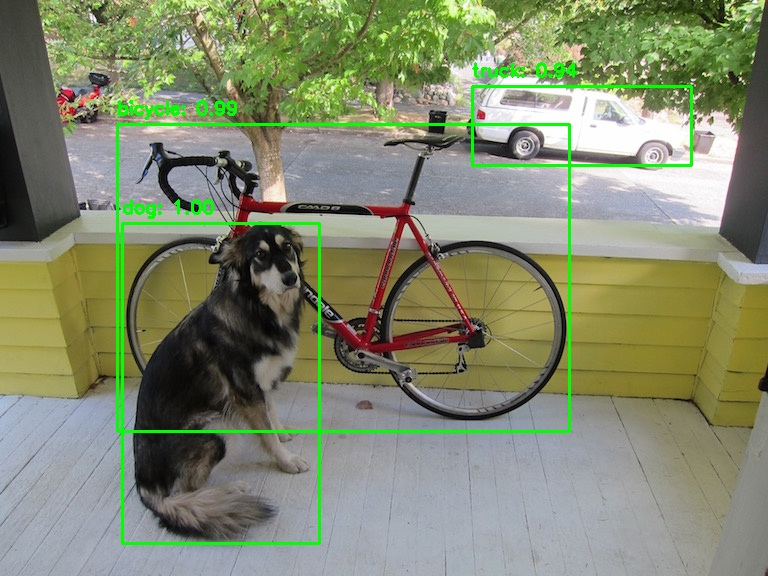

In [13]:
display(Image(filename=output_path))